# Control supervisorio localizado: línea de transferencia

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/LCS_localized_control_transfer_line.ipynb)

El notebook [`LCS_modular_control_transfer_line`](LCS_modular_control_transfer_line.ipynb) controla
la línea de transferencia con un supervisor monolítico, y con dos supervisores modulares y un
coordinador. Aquí se usa **control supervisorio localizado** (Cai y Wonham, 2010): el supervisor
monolítico $SUP$ se reparte en un controlador local $LOC_\sigma$ por cada evento controlable
$\sigma$. Cada $LOC_\sigma$ solo habilita o deshabilita su evento $\sigma$, y para decidir observa
algunos eventos de los otros componentes: esos eventos son la comunicación entre controladores.

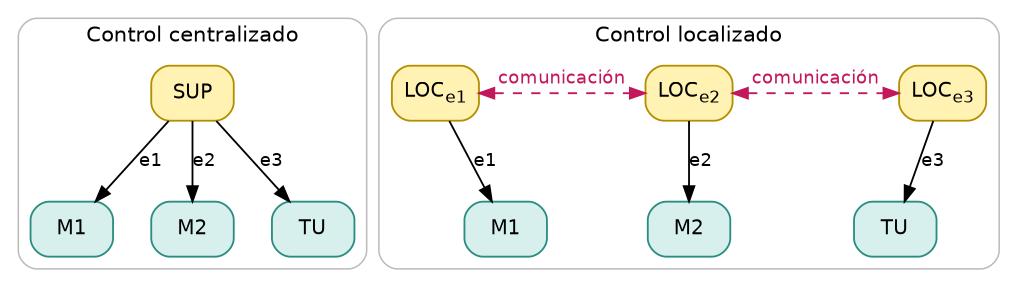

Juntos, los controladores locales deben hacer lo mismo que $SUP$:

$$L(SUP) = L(LOC_{e_1}) \parallel L(LOC_{e_2}) \parallel L(LOC_{e_3}) \parallel L(G)$$
$$L_m(SUP) = L_m(LOC_{e_1}) \parallel L_m(LOC_{e_2}) \parallel L_m(LOC_{e_3}) \parallel L_m(G)$$

La función `localize(SUP, G, agentes)` de DESlab calcula los controladores locales como la función
`localize` de TCT.

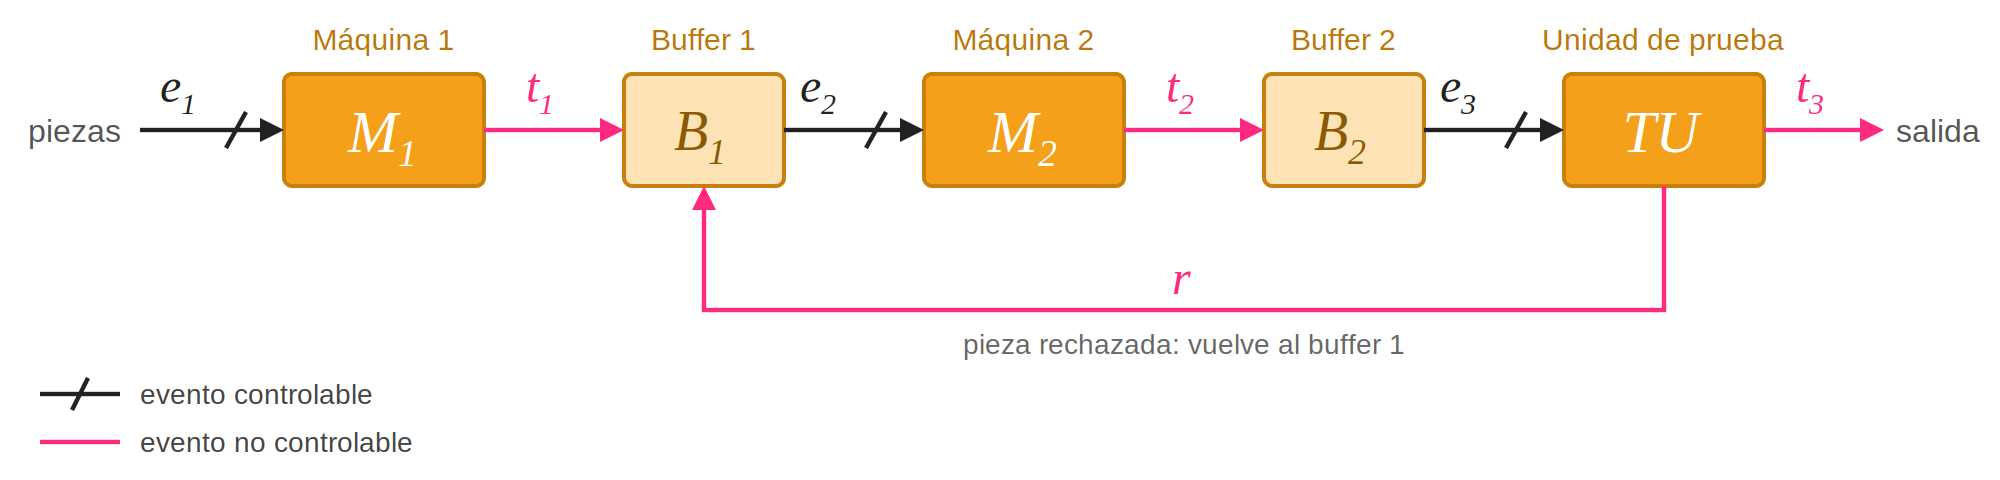

Los eventos controlables se marcan con una rayita sobre el arco y los no controlables van en
color rosado, como en los dibujos de DESlab.

| Evento | Significado | Tipo |
|---|---|---|
| $e_1$ | $M_1$ toma una pieza y empieza a trabajar | controlable |
| $t_1$ | $M_1$ termina y deja la pieza en $B_1$ | no controlable |
| $e_2$ | $M_2$ toma una pieza de $B_1$ | controlable |
| $t_2$ | $M_2$ termina y deja la pieza en $B_2$ | no controlable |
| $e_3$ | $TU$ toma una pieza de $B_2$ para probarla | controlable |
| $t_3$ | $TU$ acepta la pieza, que sale de la línea | no controlable |
| $r$ | $TU$ rechaza la pieza y la devuelve a $B_1$ | no controlable |

In [57]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
DESlab instalado desde el commit 53cbc0f


In [58]:
from deslab import *

## 1. Planta y especificaciones

Son las del notebook modular. La planta es $G = M_1 \parallel M_2 \parallel TU$; cada componente
tiene dos estados, $D$ (desocupada, inicial y marcado) y $O$ (ocupada). Las especificaciones $E_1$ y
$E_2$ son los buffers $B_1$ y $B_2$ de capacidad 1.

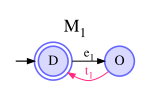

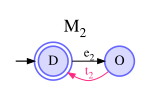

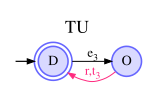

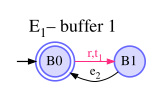

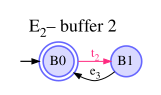

In [59]:
syms('D O B0 B1 e1 t1 e2 t2 e3 t3 r')
tabla = [(e1, 'e_1'), (t1, 't_1'), (e2, 'e_2'), (t2, 't_2'), (e3, 'e_3'), (t3, 't_3')]

M1 = fsa([D, O], [e1, t1], [(D, e1, O), (O, t1, D)], [D], [D], tabla,
         Sigcon=[e1], name='$M_1$')
M2 = fsa([D, O], [e2, t2], [(D, e2, O), (O, t2, D)], [D], [D], tabla,
         Sigcon=[e2], name='$M_2$')
TU = fsa([D, O], [e3, t3, r], [(D, e3, O), (O, t3, D), (O, r, D)], [D], [D], tabla,
         Sigcon=[e3], name='$TU$')

E1 = fsa([B0, B1], [t1, r, e2], [(B0, t1, B1), (B0, r, B1), (B1, e2, B0)], [B0], [B0], tabla,
         Sigcon=[e2], name='$E_1$ -- buffer 1')
E2 = fsa([B0, B1], [t2, e3], [(B0, t2, B1), (B1, e3, B0)], [B0], [B0], tabla,
         Sigcon=[e3], name='$E_2$ -- buffer 2')
draw(M1, M2, TU, E1, E2)

## 2. Supervisor monolítico

Los estados de $SUP$ son tuplas (estado de $M_1$, de $M_2$, de $TU$, de $B_1$, de $B_2$). Para leer
las tablas de las secciones siguientes, la celda los numera 0, 1, 2, ... a lo ancho desde el estado
inicial, con la misma numeración de TCT y de las diapositivas de clase.

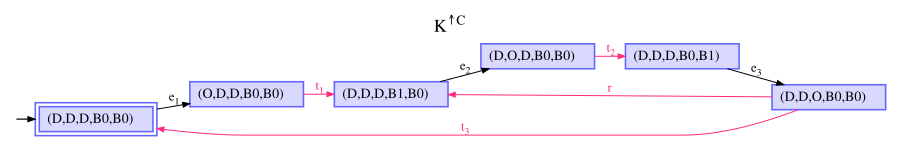

In [60]:
G = (M1 // M2 // TU).setpar(name='$G = M_1 \\parallel M_2 \\parallel TU$')
SUP = supcontrollable(G // E1 // E2, G).setpar(style='rectangle')
SUP



## 5. Cubrimiento de control y la función `localize`

Un **cubrimiento de control** $C_\sigma = \{Y_i\}$ agrupa los estados de $SUP$ en conjuntos
$Y_i$, que juntos contienen todos los estados, tales que:

1. los estados de cada $Y_i$ son consistentes dos a dos;
2. un mismo evento lleva todos los estados de $Y_i$ que lo tienen a un mismo conjunto $Y_j$, para que
   $LOC_\sigma$ sea determinista.

Cada conjunto $Y_i$ es un estado de $LOC_\sigma$: hay una transición $\alpha$ de $Y_i$ a $Y_j$ si
algún estado de $Y_i$ va con $\alpha$ a un estado de $Y_j$, y $Y_i$ es marcado si tiene un estado
marcado de $SUP$.

`localize(SUP, G, agentes)` construye el cubrimiento con el procedimiento de TCT: recorre los estados
de $SUP$ en orden y junta cada par, con los sucesores que hace falta juntar para cumplir la condición
2, si todos los estados juntados quedan consistentes dos a dos. Es un procedimiento voraz: da
controladores pequeños, no necesariamente los mínimos.

Los agentes son componentes de la planta, y el controlador de cada agente habilita y deshabilita sus
eventos controlables. En la línea de transferencia cada componente tiene un solo evento controlable,
así que localizar por componente es localizar por evento: $M_1$ da $LOC_{e_1}$, $M_2$ da $LOC_{e_2}$ y
$TU$ da $LOC_{e_3}$. .

LOC_e1: 2 estados | eventos: ['e1', 't1', 't3']
LOC_e2: 3 estados | eventos: ['e2', 'e3', 'r', 't1', 't2']
LOC_e3: 3 estados | eventos: ['e2', 'e3', 'r', 't1', 't2']


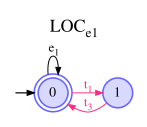

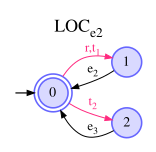

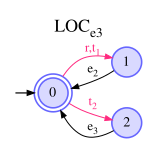

frozenset({'e2', 'e3'})

In [ ]:
LOC_e1, LOC_e2, LOC_e3 = localize(SUP, G, [M1, M2, TU])
LOC_e1 = LOC_e1.setpar(name='$LOC_{e_1}$', )
LOC_e2 = LOC_e2.setpar(name='$LOC_{e_2}$')
LOC_e3 = LOC_e3.setpar(name='$LOC_{e_3}$')
for nombre, L in [('LOC_e1', LOC_e1), ('LOC_e2', LOC_e2), ('LOC_e3', LOC_e3)]:
    print(f'{nombre}: {len(L)} estados | eventos: {sorted(L.Sigma)}')
draw(LOC_e1, LOC_e2, LOC_e3)


## 7. Verificación

Los controladores funcionan junto con la planta: un evento ocurre solo si la planta y todos los
controladores que lo tienen lo permiten. La celda comprueba las dos ecuaciones del comienzo y que
$G \parallel LOC_{e_1} \parallel LOC_{e_2} \parallel LOC_{e_3}$ es isomorfo a $SUP$.

¿G || LOC es isomorfo a SUP? True


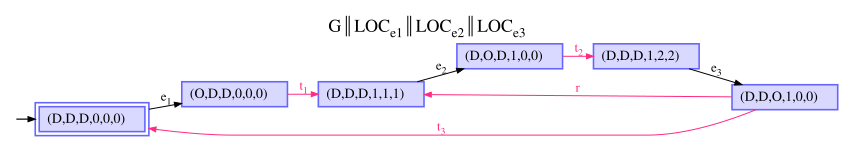

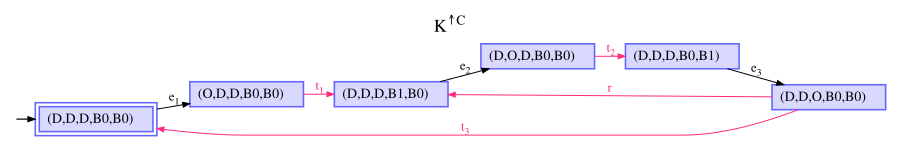

In [62]:
LAZO = (G // LOC_e1 // LOC_e2 // LOC_e3).setpar(name='$G \\parallel LOC_{e_1} \\parallel LOC_{e_2} \\parallel LOC_{e_3}$', style='rectangle')
print('¿G || LOC es isomorfo a SUP?', are_isomorphic(LAZO, SUP))
draw(LAZO)
draw(SUP)